# PRCP-1017: Auto Price Prediction

## Project Goal

The primary objective of this project is to analyze the factors that influence car prices and develop a predictive model capable of estimating the price of a car based on its features.

This project aims to:

- Perform comprehensive data cleaning and preprocessing.
- Conduct Exploratory Data Analysis (EDA) to understand the dataset and identify key patterns.
- Analyze the relationship between car features and their prices.
- Build and evaluate multiple machine learning models for price prediction.
- Compare model performance using appropriate evaluation metrics.
- Identify the most important factors affecting car prices.
- Provide business insights and recommendations to help management make informed decisions regarding vehicle design, pricing strategies, and market positioning.

By successfully completing this project, management can better understand the pricing dynamics of automobiles and make data-driven decisions when introducing new vehicles into the market.

## Business Problem Statement

A car manufacturing company wants to understand how different vehicle characteristics influence car prices. By identifying the key factors affecting pricing, the company can optimize vehicle specifications, improve pricing strategies, and better position products in the market.

To address this problem, a machine learning model will be developed to predict car prices using various vehicle attributes such as engine size, horsepower, curb weight, fuel type, and other technical specifications.

In [1]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

In [38]:

# Load the original headerless Automobile dataset correctly.

column_names = [
    "symboling", "normalized_losses", "make", "fuel_type",
    "aspiration", "num_of_doors", "body_style", "drive_wheels",
    "engine_location", "wheel_base", "length", "width", "height",
    "curb_weight", "engine_type", "num_of_cylinders", "engine_size",
    "fuel_system", "bore", "stroke", "compression_ratio",
    "horsepower", "peak_rpm", "city_mpg", "highway_mpg", "price"
]

df = pd.read_csv(
    "../data/auto_imports.csv",
    header=None,
    names=column_names,
    na_values="?"
)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (201, 26)


,symboling,normalized_losses,make,fuel_type,aspiration,num_of_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450


In [39]:
# Assign column names

df.columns = [
    'symboling','normalized_losses','make','fuel_type',
    'aspiration','num_of_doors','body_style',
    'drive_wheels','engine_location','wheel_base',
    'length','width','height','curb_weight',
    'engine_type','num_of_cylinders','engine_size',
    'fuel_system','bore','stroke',
    'compression_ratio','horsepower','peak_rpm',
    'city_mpg','highway_mpg','price'
]

df.head()

,symboling,normalized_losses,make,fuel_type,aspiration,num_of_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450


In [40]:
df.shape

(201, 26)

Number of rows and columns

In [41]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          201 non-null    int64  
 1   normalized_losses  164 non-null    float64
 2   make               201 non-null    str    
 3   fuel_type          201 non-null    str    
 4   aspiration         201 non-null    str    
 5   num_of_doors       199 non-null    str    
 6   body_style         201 non-null    str    
 7   drive_wheels       201 non-null    str    
 8   engine_location    201 non-null    str    
 9   wheel_base         201 non-null    float64
 10  length             201 non-null    float64
 11  width              201 non-null    float64
 12  height             201 non-null    float64
 13  curb_weight        201 non-null    int64  
 14  engine_type        201 non-null    str    
 15  num_of_cylinders   201 non-null    str    
 16  engine_size        201 non-null    in

In [42]:
# Check duplicates

df.duplicated().sum()

np.int64(0)

In [43]:
# Replace placeholder missing values and convert numeric columns

df.replace("?", np.nan, inplace=True)

numeric_columns = [
    "normalized_losses", "bore", "stroke", "horsepower",
    "peak_rpm", "price"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# A missing target cannot be imputed for supervised training; exclude those rows.
missing_price_rows = int(df["price"].isna().sum())
if missing_price_rows:
    df = df.dropna(subset=["price"]).copy()

print("Numeric columns converted.")
print(f"Rows excluded because target price was missing: {missing_price_rows}")
print(f"Dataset shape after target check: {df.shape}")

Numeric columns converted.
Rows excluded because target price was missing: 0
Dataset shape after target check: (201, 26)


In [44]:
print(df.isnull().sum())

symboling             0
normalized_losses    37
make                  0
fuel_type             0
aspiration            0
num_of_doors          2
body_style            0
drive_wheels          0
engine_location       0
wheel_base            0
length                0
width                 0
height                0
curb_weight           0
engine_type           0
num_of_cylinders      0
engine_size           0
fuel_system           0
bore                  4
stroke                4
compression_ratio     0
horsepower            2
peak_rpm              2
city_mpg              0
highway_mpg           0
price                 0
dtype: int64


In [45]:
missing_before = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': round((df.isnull().sum()/len(df))*100,2)
})

missing_before.sort_values(
    by='Missing Percentage',
    ascending=False
)

,Missing Count,Missing Percentage
normalized_losses,37,18.41
stroke,4,1.99
bore,4,1.99
peak_rpm,2,1.00
horsepower,2,1.00
num_of_doors,2,1.00
symboling,0,0.00
make,0,0.00
fuel_type,0,0.00
aspiration,0,0.00


The dataset contains missing values in the `normalized_losses`, `num_of_doors`, `bore`, `stroke`, `horsepower`, and `peak_rpm` columns.

The source data uses `?` as a placeholder for missing values. These placeholders are converted to `NaN`, and numeric fields are converted to appropriate numeric data types before exploratory analysis.

In [46]:
missing_after = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': round((df.isnull().sum()/len(df))*100,2)
})

missing_after.sort_values(
    by='Missing Percentage',
    ascending=False
)

,Missing Count,Missing Percentage
normalized_losses,37,18.41
stroke,4,1.99
bore,4,1.99
peak_rpm,2,1.00
horsepower,2,1.00
num_of_doors,2,1.00
symboling,0,0.00
make,0,0.00
fuel_type,0,0.00
aspiration,0,0.00


### Interpretation of Missing Values

The initial dataset contains 51 missing values across six feature columns. These missing values are intentionally retained in the original DataFrame (`df`) because missing-value treatment is performed within the machine-learning preprocessing pipeline.

The `SimpleImputer` is configured to handle missing values as follows:

- **Numerical features:** Missing values are replaced with the median of the corresponding feature.
- **Categorical features:** Missing values are replaced with the most frequent value of the corresponding feature.

The imputation process is fitted as part of the training pipeline. This ensures that imputation statistics are learned from the training data rather than the test data, helping prevent data leakage.

Therefore, the missing-value count in the original DataFrame remains unchanged, while the transformed training data contains zero missing values.

**Conclusion:** Missing-value handling is successfully implemented within the preprocessing pipeline. Keeping the original dataset unchanged preserves the raw data and ensures that preprocessing is applied consistently during model training and prediction.

In [47]:
# Summary statistics

df.describe()

,symboling,normalized_losses,wheel_base,length,width,height,curb_weight,engine_size,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
count,201.000000,164.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,197.000000,197.000000,201.000000,199.000000,199.000000,201.000000,201.000000,201.000000
mean,0.840796,122.000000,98.797015,174.200995,65.889055,53.766667,2555.666667,126.875622,3.330711,3.256904,10.164279,103.396985,5117.587940,25.179104,30.686567,13207.129353
std,1.254802,35.442168,6.066366,12.322175,2.101471,2.447822,517.296727,41.546834,0.270793,0.319256,4.004965,37.553843,480.521824,6.423220,6.815150,7947.066342
min,-2.000000,65.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,0.000000,94.000000,94.500000,166.800000,64.100000,52.000000,2169.000000,98.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7775.000000
50%,1.000000,115.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,2.000000,150.000000,102.400000,183.500000,66.600000,55.500000,2926.000000,141.000000,3.590000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16500.000000
max,3.000000,256.000000,120.900000,208.100000,72.000000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,262.000000,6600.000000,49.000000,54.000000,45400.000000


In [48]:
print("Minimum Price :", df['price'].min())
print("Maximum Price :", df['price'].max())
print("Average Price :", round(df['price'].mean(),2))
print("Median Price :", df['price'].median())

Minimum Price : 5118
Maximum Price : 45400
Average Price : 13207.13
Median Price : 10295.0


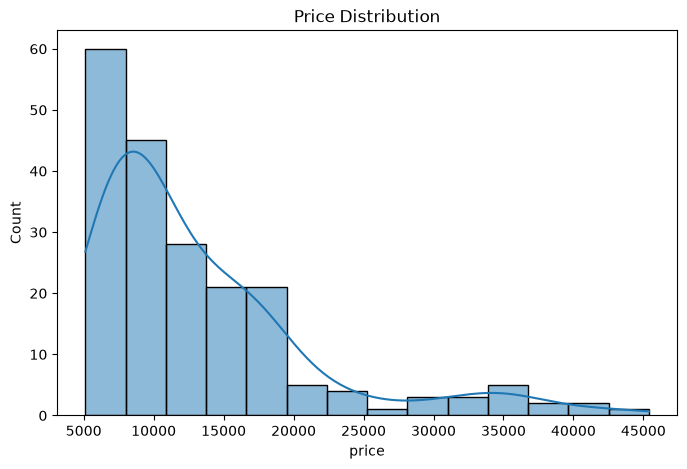

In [49]:
# Distribution of car prices

plt.figure(figsize=(8,5))

sns.histplot(df['price'], kde=True)

plt.title("Price Distribution")

plt.show()

Price distribution is right skewed.

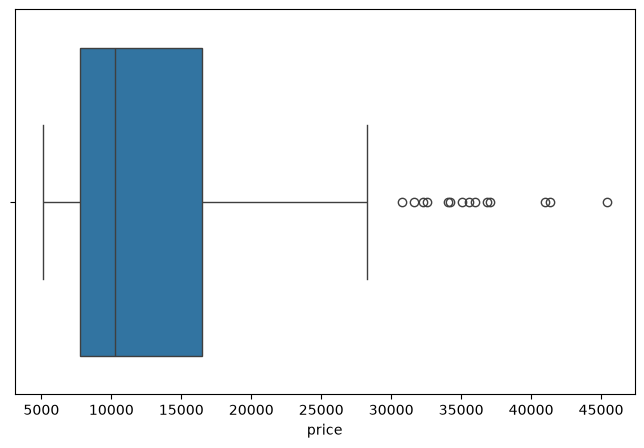

In [50]:
# Detect outliers

plt.figure(figsize=(8,5))

sns.boxplot(x=df['price'])

plt.show()

Some high priced vehicles are present.

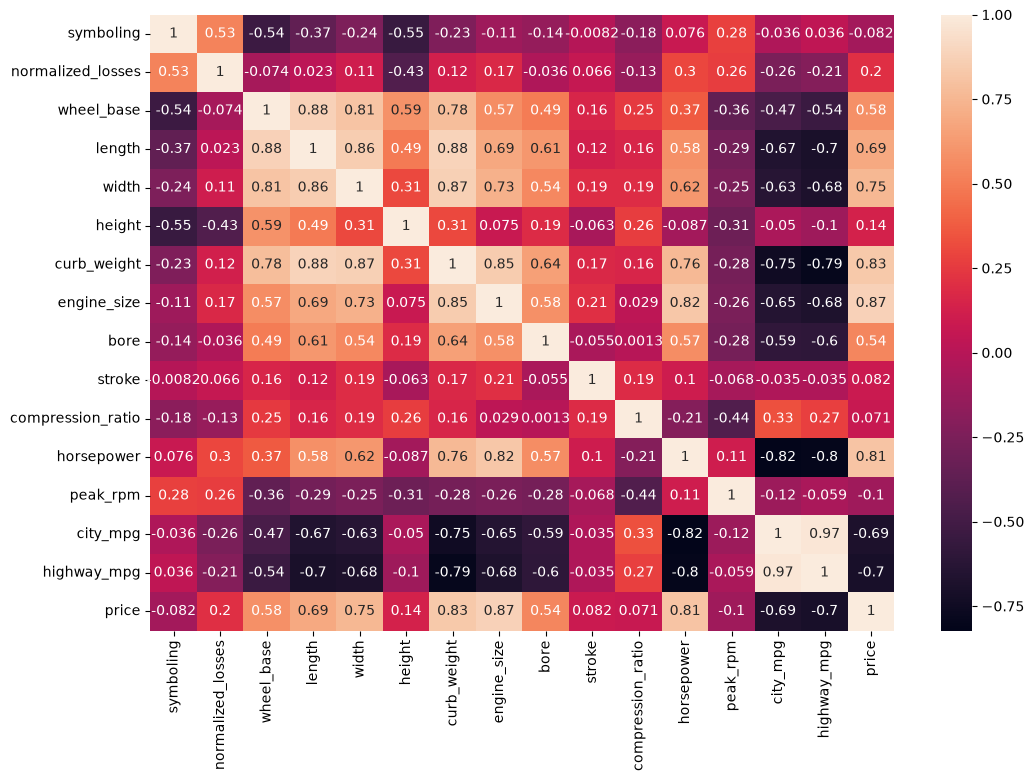

In [51]:
# Correlation between numerical columns

plt.figure(figsize=(12,8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True
)

plt.show()

Engine size and horsepower show strong correlation with price.

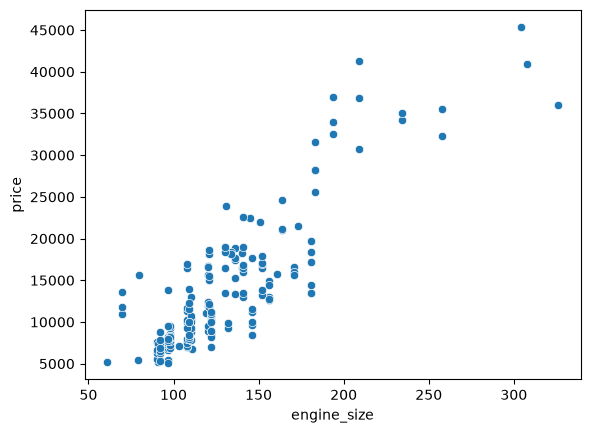

In [52]:
# Relationship between engine size and price

sns.scatterplot(
    x='engine_size',
    y='price',
    data=df
)

plt.show()

Price increases as engine size increases.

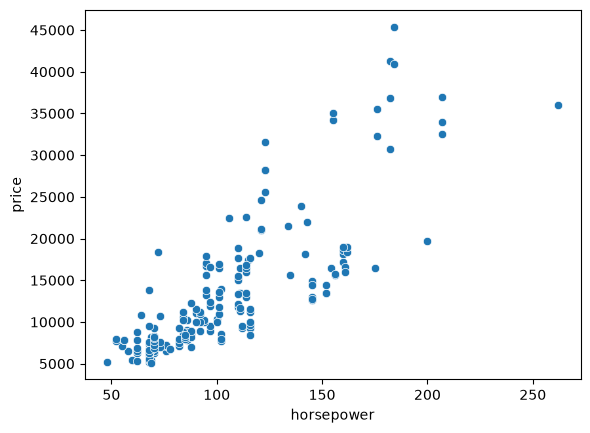

In [53]:
# Relationship between horsepower and price

sns.scatterplot(
    x='horsepower',
    y='price',
    data=df
)

plt.show()

Cars with higher horsepower have higher prices.

In [54]:
# Separate features and target variable

X = df.drop("price", axis=1)
y = df["price"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (201, 25)
Target shape: (201,)


In [55]:
numeric_string_columns = [
    "normalized_losses",
    "bore",
    "stroke",
    "horsepower",
    "peak_rpm"
]

for col in numeric_string_columns:
    X[col] = pd.to_numeric(X[col], errors="coerce")

print("Data types updated successfully.")
print(X[numeric_string_columns].dtypes)

Data types updated successfully.
normalized_losses    float64
bore                 float64
stroke               float64
horsepower           float64
peak_rpm             float64
dtype: object


In [56]:
print(X.dtypes)

symboling              int64
normalized_losses    float64
make                     str
fuel_type                str
aspiration               str
num_of_doors             str
body_style               str
drive_wheels             str
engine_location          str
wheel_base           float64
length               float64
width                float64
height               float64
curb_weight            int64
engine_type              str
num_of_cylinders         str
engine_size            int64
fuel_system              str
bore                 float64
stroke               float64
compression_ratio    float64
horsepower           float64
peak_rpm             float64
city_mpg               int64
highway_mpg            int64
dtype: object


In [57]:
# Identify numerical and categorical features after data type correction

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["str"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['symboling', 'normalized_losses', 'wheel_base', 'length', 'width', 'height', 'curb_weight', 'engine_size', 'bore', 'stroke', 'compression_ratio', 'horsepower', 'peak_rpm', 'city_mpg', 'highway_mpg']

Categorical features:
['make', 'fuel_type', 'aspiration', 'num_of_doors', 'body_style', 'drive_wheels', 'engine_location', 'engine_type', 'num_of_cylinders', 'fuel_system']


In [58]:
# Create preprocessing pipelines

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [59]:
# Import train_test_split function

from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
# 80% of data is used for training
# 20% of data is used for testing

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

Train-Test Split is performed to evaluate the model's performance on unseen data.

X_train:
Contains the feature data used for training the model.

X_test:
Contains the feature data used for testing the model.

y_train:
Contains the actual car prices used during model training.

y_test:
Contains the actual car prices used for model evaluation.

80% of the dataset is allocated for training and 20% for testing.

The random_state parameter is set to 42 to ensure reproducibility of results.

In [60]:
# Check the shape of training and testing datasets

print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)

print("y_train Shape:", y_train.shape)
print("y_test Shape:", y_test.shape)

X_train Shape: (160, 25)
X_test Shape: (41, 25)
y_train Shape: (160,)
y_test Shape: (41,)


The dataset was successfully divided into training and testing sets.

Training data is used to train the machine learning models, while testing data is used to evaluate model performance on unseen records.

In [61]:
# Create Linear Regression pipeline

lr_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

# Train the pipeline
lr_pipeline.fit(X_train, y_train)

print("Linear Regression pipeline trained successfully.")

Linear Regression pipeline trained successfully.


Linear Regression is used as a baseline model to understand the relationship between independent variables and car price.

In [73]:

# Verify missing values after preprocessing

import numpy as np
from scipy import sparse

# Transform training features using the fitted preprocessor
X_train_processed = lr_pipeline.named_steps["preprocessor"].transform(X_train)

# Count missing values in the processed data
if sparse.issparse(X_train_processed):
    missing_count = np.isnan(X_train_processed.data).sum()
else:
    missing_count = np.isnan(X_train_processed).sum()

print("Original training data shape:", X_train.shape)
print("Processed training data shape:", X_train_processed.shape)
print("Missing values after preprocessing:", missing_count)


Original training data shape: (160, 25)
Processed training data shape: (160, 64)
Missing values after preprocessing: 0


In [62]:
# Create Random Forest Regression pipeline

rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        random_state=42
    ))
])

# Train the pipeline
rf_pipeline.fit(X_train, y_train)

print("Random Forest pipeline trained successfully.")

Random Forest pipeline trained successfully.


Random Forest combines multiple decision trees and generally provides better prediction accuracy than a single model.

The trained Random Forest model predicts car prices for the test data.

In [63]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predictions
lr_pred = lr_pipeline.predict(X_test)
rf_pred = rf_pipeline.predict(X_test)

# Linear Regression metrics
lr_mae = mean_absolute_error(y_test, lr_pred)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))
lr_r2 = r2_score(y_test, lr_pred)

# Random Forest metrics
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

# Display results
print("Linear Regression")
print(f"MAE:  {lr_mae:.2f}")
print(f"RMSE: {lr_rmse:.2f}")
print(f"R²:   {lr_r2:.4f}")

print("\nRandom Forest")
print(f"MAE:  {rf_mae:.2f}")
print(f"RMSE: {rf_rmse:.2f}")
print(f"R²:   {rf_r2:.4f}")

Linear Regression
MAE:  2028.65
RMSE: 3295.57
R²:   0.9112

Random Forest
MAE:  1899.16
RMSE: 2946.08
R²:   0.9291


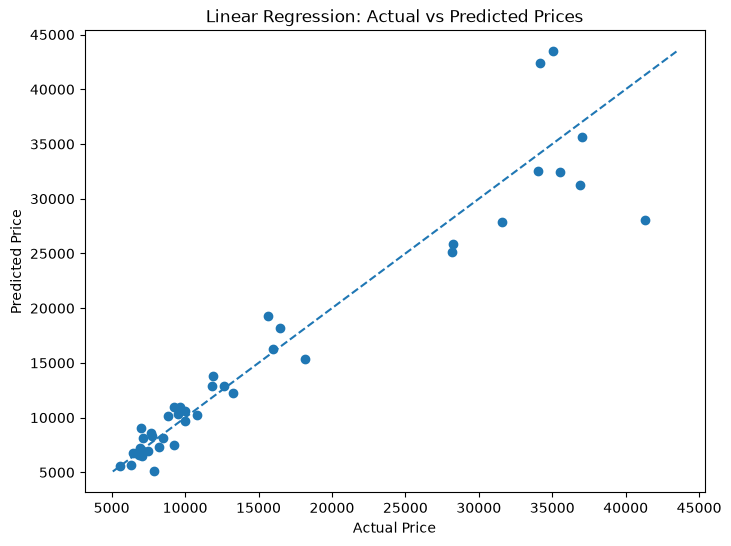

In [64]:
# Linear Regression: Actual vs Predicted Prices

plt.figure(figsize=(8, 6))

plt.scatter(y_test, lr_pred)

# Perfect prediction reference line
min_price = min(y_test.min(), lr_pred.min())
max_price = max(y_test.max(), lr_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Linear Regression: Actual vs Predicted Prices")

plt.show()

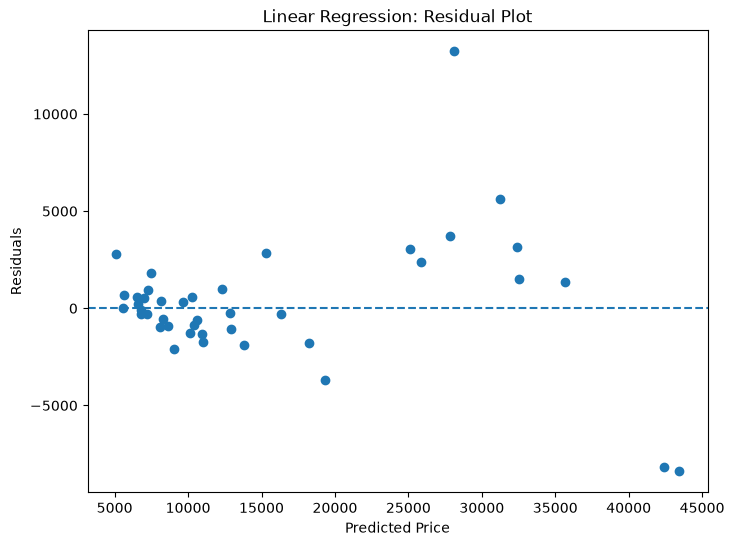

In [65]:
# Calculate Linear Regression residuals
lr_residuals = y_test - lr_pred

# Plot residuals
plt.figure(figsize=(8, 6))

plt.scatter(lr_pred, lr_residuals)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Linear Regression: Residual Plot")

plt.show()

## Random Forest Model Evaluation

After training the Random Forest Regression model, its performance was evaluated using multiple regression metrics to measure prediction accuracy and model effectiveness.

The following metrics were used:

- **Mean Absolute Error (MAE):** Measures the average absolute difference between actual and predicted car prices.
- **Root Mean Squared Error (RMSE):** Measures the standard deviation of prediction errors and penalizes larger errors more heavily.
- **R² Score (Coefficient of Determination):** Indicates how well the model explains the variation in automobile prices. A value closer to 1 represents better model performance.

These metrics provide a comprehensive assessment of the Random Forest model's ability to predict vehicle prices accurately.

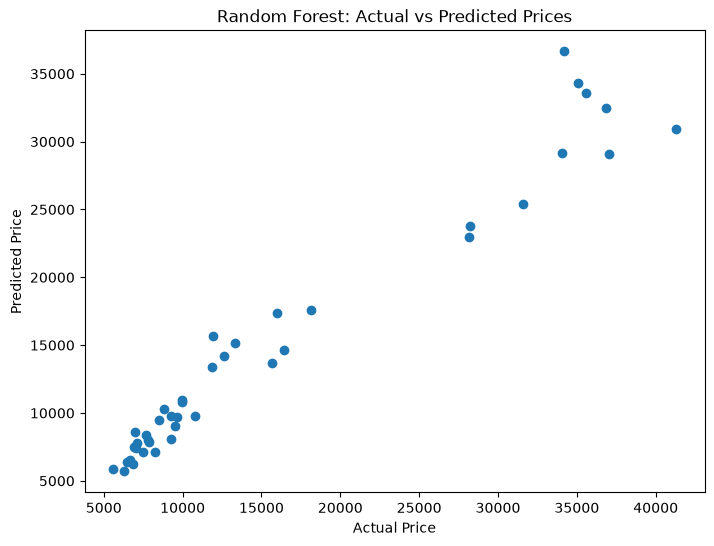

In [66]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, rf_pred)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Random Forest: Actual vs Predicted Prices")

plt.show()

### Observation

The scatter plot demonstrates the relationship between actual and predicted automobile prices generated by the Random Forest model. A strong clustering of points around the diagonal pattern suggests high prediction accuracy and good model performance.

Compared to Linear Regression, the Random Forest model is often better at capturing complex, non-linear relationships within the data, resulting in predictions that are closer to the actual vehicle prices.

The model with the higher R² Score is considered the better-performing model for car price prediction.

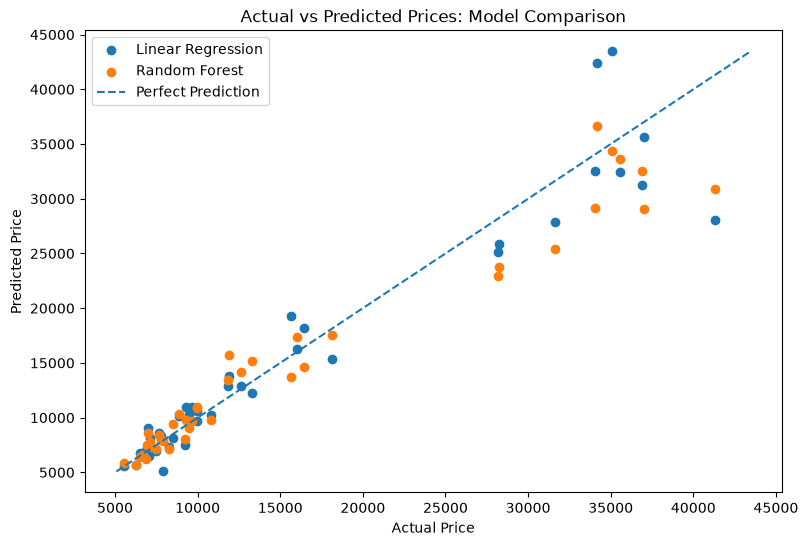

In [67]:
# Compare Actual vs Predicted Prices for both models

plt.figure(figsize=(9, 6))

plt.scatter(y_test, lr_pred, label="Linear Regression")
plt.scatter(y_test, rf_pred, label="Random Forest")

# Perfect prediction reference line
min_price = min(y_test.min(), lr_pred.min(), rf_pred.min())
max_price = max(y_test.max(), lr_pred.max(), rf_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Prices: Model Comparison")
plt.legend()

plt.show()

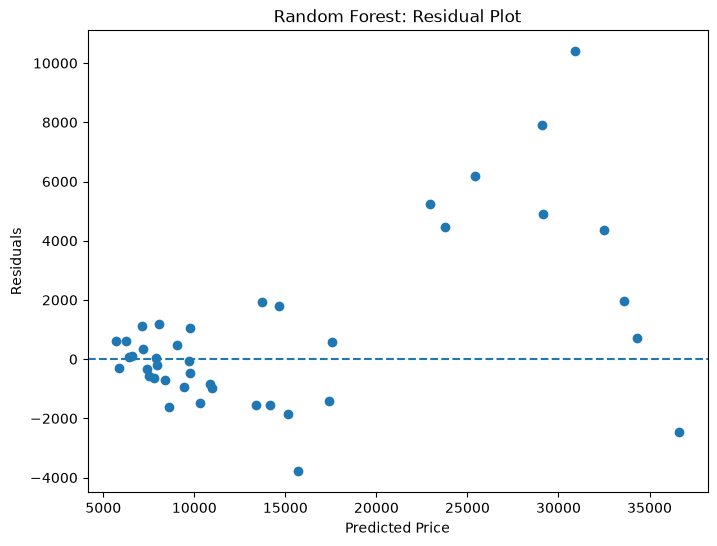

In [68]:
# Calculate residuals
rf_residuals = y_test - rf_pred

# Plot residuals
plt.figure(figsize=(8, 6))

plt.scatter(rf_pred, rf_residuals)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Random Forest: Residual Plot")

plt.show()

In [69]:
# Compare Linear Regression and Random Forest performance

comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [lr_mae, rf_mae],
    'RMSE': [lr_rmse, rf_rmse],
    'R2 Score': [lr_r2, rf_r2]
})

comparison = comparison.round(4)

comparison

,Model,MAE,RMSE,R2 Score
0,Linear Regression,2028.6513,3295.566,0.9112
1,Random Forest,1899.1573,2946.078,0.9291


In [70]:
# Identify important features affecting car price

# Get the fitted preprocessing and Random Forest model
preprocessor_fitted = rf_pipeline.named_steps["preprocessor"]
rf_model = rf_pipeline.named_steps["model"]

# Get feature names after preprocessing
feature_names = preprocessor_fitted.get_feature_names_out()

# Create feature importance dataframe
importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

# Sort features by importance
importance = importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 10 important features
importance.head(10)

,Feature,Importance
6,num__curb_weight,0.434808
7,num__engine_size,0.307027
14,num__highway_mpg,0.054771
11,num__horsepower,0.053670
13,num__city_mpg,0.039999
4,num__width,0.030210
2,num__wheel_base,0.011881
16,cat__make_bmw,0.009707
12,num__peak_rpm,0.007236
1,num__normalized_losses,0.006987


Feature Importance helps identify which variables have the greatest influence on car prices.

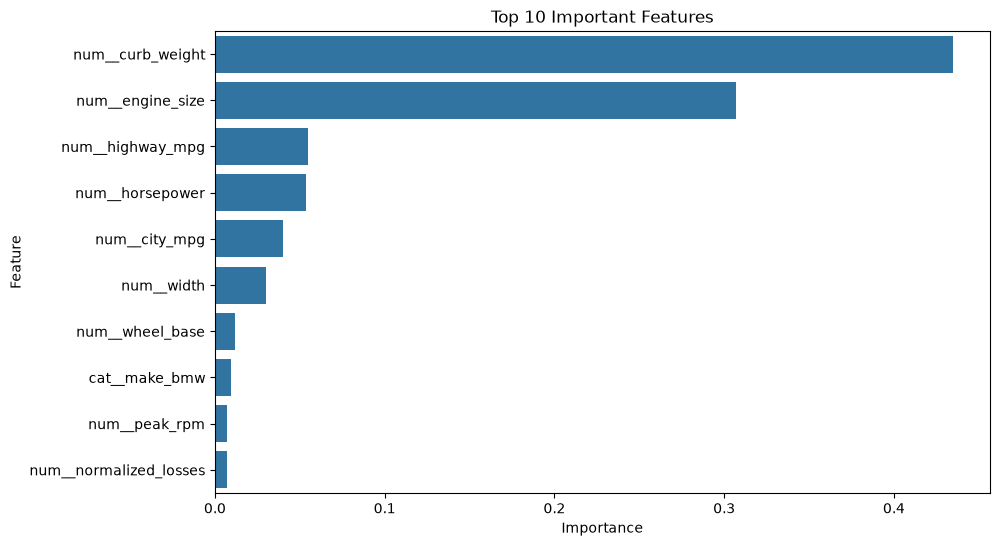

In [71]:
# Display top 10 important features

top10 = importance.sort_values(
    by='Importance',
    ascending=False
).head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    x='Importance',
    y='Feature',
    data=top10
)

plt.title("Top 10 Important Features")

plt.show()

In [72]:
best_model = comparison.loc[
    comparison['R2 Score'].idxmax(),
    'Model'
]

print(f"Best Performing Model: {best_model}")

Best Performing Model: Random Forest


The evaluation results are summarized in the model comparison table above. Use the metrics generated by the current clean notebook run; do not rely on previously saved values if the dataset loading or preprocessing has changed.

## Conclusion

1. Data cleaning, exploratory data analysis, and preprocessing were performed to prepare the automobile dataset for machine learning.

2. Two regression models, Linear Regression and Random Forest Regression, were developed to predict automobile prices.

3. Both models were evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the coefficient of determination (R² score).

4. The model comparison indicates which regression algorithm performs better on the test dataset based on prediction errors and goodness of fit. The final model was selected using the evaluation results generated by the executed notebook.

5. Feature importance analysis was used to identify the vehicle characteristics that contribute most to the Random Forest model's predictions.

6. Overall, this project demonstrates an end-to-end machine learning workflow for automobile price prediction, including data preparation, preprocessing, model development, evaluation, and interpretation. Further validation and hyperparameter tuning could help assess and improve the model's performance.

## Business Impact

The developed machine learning model can assist automobile dealers, manufacturers, and customers in estimating vehicle prices based on technical specifications and design characteristics.

By identifying the most influential features affecting price, the model can support data-driven pricing decisions and market analysis.